## Environment and imports

In [ ]:
# Install the packages that Colab does not have by default
# torchaudio and torchao are removed because their versions clash with torch/peft, and we don't need them
!pip uninstall -y -q torchaudio torchao
!pip install -q --no-cache-dir pillow
!pip install -q peft pdfplumber

In [ ]:
import pdfplumber
from pathlib import Path
from transformers.utils import logging
import os
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import math
import json

import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

from datasets import Dataset
from transformers import Trainer, DataCollatorForLanguageModeling

from peft import LoraConfig, get_peft_model, PeftModel

import PIL


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd "/content/drive/MyDrive/SIT319_ass"

/content/drive/MyDrive/SIT319_ass


## Fixed protocol summary

| Item | Required setting |
|---|---|
| Base model | `distilgpt2` |
| Tokenizer | tokenizer associated with `distilgpt2` |
| Training text | `undrip_train.txt` |
| Validation text | `undrip_val.txt` |
| Held-out related evaluation text | `economic_test.txt` |
| Required metric | perplexity |
| Generation prompt | `Economic self-determination for First Nations peoples requires` |



## Fixed configuration values for required results


In [ ]:
# Fixed configuration values.
# These are provided so all students report results under the same protocol.

BASE_MODEL = "distilgpt2"

TEXT_FILES = {
    "train": "undrip_train.txt",
    "validation": "undrip_val.txt",
    "test": "economic_test.txt",
}

GENERATION_PROMPT = "Economic self-determination for First Nations peoples requires"

TOKENISATION_CONFIG = {
    "block_size": 128,
}

# Settings for perplexity evaluation.
# These are not Hugging Face TrainingArguments.
PERPLEXITY_MAX_LENGTH = 128
PERPLEXITY_STRIDE = 128

GENERATION_CONFIG = {
    "max_new_tokens": 80,
    "do_sample": False,
}


FULL_FINE_TUNING_CONFIG = {
    "output_dir": "./distilgpt2-full-finetuned",
    "num_train_epochs": 1,
    "learning_rate": 5e-5,
    "per_device_train_batch_size": 2,
    "per_device_eval_batch_size": 2,
    "weight_decay": 0.01,
    "logging_steps": 20,
    "save_strategy": "no",
    "report_to": "none",
}

LORA_CONFIG = {
    "r": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "target_modules": ["c_attn"],
    "bias": "none",
    "task_type": "CAUSAL_LM",
}

# LORA_CONFIG controls the LoRA adapter itself: rank, scaling, dropout,
# and target modules.

# LORA_TRAINING_CONFIG controls how the LoRA adapter is trained.
LORA_TRAINING_CONFIG = {
    "output_dir": "./distilgpt2-lora-finetuned",
    "num_train_epochs": 1,
    "learning_rate": 1e-4,
    "per_device_train_batch_size": 2,
    "per_device_eval_batch_size": 2,
    "weight_decay": 0.01,
    "logging_steps": 20,
    "save_strategy": "no",
    "report_to": "none",
}


## Required tokenizer and model setup

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, TrainingArguments

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

# GPT-style tokenizers such as distilgpt2 do not define a separate padding token by default.
# Use the EOS token as the padding token so that batched training/evaluation can run.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

pretrained_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL)
pretrained_model.resize_token_embeddings(len(tokenizer))
pretrained_model.config.pad_token_id = tokenizer.pad_token_id

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

## Reproducibility

In [ ]:
# Reproducibility
# This reduces run-to-run variation in data shuffling, model initialisation, and generation.
# Exact reproducibility is still not guaranteed on all GPU/CUDA setups.

import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print(f"Seed set to {SEED}")


Seed set to 42


# Data preparation and pretrained baseline (25%)


##  Source documents and extraction method

**Fine-tuning source document:** Joint Standing Committee on Aboriginal and Torres Strait Islander Affairs (2023). *Inquiry into the application of the United Nations Declaration on the Rights of Indigenous Peoples in Australia*. Parliament of Australia. (PDF, 220 pages)

**Held-out related evaluation source document:** Joint Standing Committee on Aboriginal and Torres Strait Islander Affairs (2024). *Inquiry into economic self-determination and opportunities for First Nations Australians*. Parliament of Australia. (PDF, 194 pages)

**Extraction method**  
Both reports were only available as PDFs, so I used pdfplumber to extract the text. I kept only the main report pages and dropped the cover, contents, recommendations list and appendices. Footnotes were removed by keeping only characters with font size ≥ 10pt, since footnotes use 9pt. I then applied the brief's clean_text steps, plus removing paragraph numbers and lines containing only page numbers. Finally, I split the cleaned UNDRIP text 80/20 by characters.

In [ ]:
def keepBigText(obj):
    # keep everything that is not a character
    if obj["object_type"] != "char":
        return True
    # keep characters of the main text
    if obj["size"] >= 10:
        return True
    return False

def extractPdfText(pdfPath, firstPage, lastPage):
    allText = ""
    pdf = pdfplumber.open(pdfPath)
    for i in range(firstPage, lastPage):
        page = pdf.pages[i]
        page = page.filter(keepBigText)
        pageText = page.extract_text()
        if pageText:
            allText = allText + pageText + "\n"
    pdf.close()
    return allText

In [ ]:
# only extract if the raw file is not already saved in Drive
if not Path("undrip_raw.txt").exists():
    # pages 22-192 is the main report (skip cover, contents and appendices)
    undripText = extractPdfText("undrip_report.pdf", 22, 192)
    Path("undrip_raw.txt").write_text(undripText, encoding="utf-8")

if not Path("economic_raw.txt").exists():
    # pages 24-180is the main report (skip cover, contents and appendices)
    economicText = extractPdfText("economic_report.pdf", 24, 180)
    Path("economic_raw.txt").write_text(economicText, encoding="utf-8")

print("Raw text files are ready")

Raw text files are ready


In [ ]:
def isNumberLine(line):
    # True if the line has only digits, dots or roman numeral letters (page numbers)
    for ch in line:
        if ch not in "0123456789.ivxlc":
            return False
    return True

def removeParagraphNumber(line):
    # "1.36 In a report..." -> "In a report..."
    parts = line.split(" ", 1)
    if len(parts) == 2:
        firstWord = parts[0]
        if "." in firstWord and firstWord.replace(".", "").isdigit():
            return parts[1]
    return line

def cleanText(text):
    cleanLines = []
    for line in text.splitlines():
        line = line.strip()
        if len(line) == 0:
            continue
        if isNumberLine(line):
            continue
        line = removeParagraphNumber(line)
        cleanLines.append(line)
    return "\n".join(cleanLines)

def splitText(text, trainRatio=0.8):
    splitIndex = int(len(text) * trainRatio)
    trainPart = text[:splitIndex]
    valPart = text[splitIndex:]
    return trainPart, valPart

In [ ]:
undripRaw = Path("undrip_raw.txt").read_text(encoding="utf-8")
economicRaw = Path("economic_raw.txt").read_text(encoding="utf-8")

undripClean = cleanText(undripRaw)
economicClean = cleanText(economicRaw)

undripTrain, undripVal = splitText(undripClean, 0.8)

Path("undrip_train.txt").write_text(undripTrain, encoding="utf-8")
Path("undrip_val.txt").write_text(undripVal, encoding="utf-8")
Path("economic_test.txt").write_text(economicClean, encoding="utf-8")

print("undrip_train.txt :", len(undripTrain), "characters")
print("undrip_val.txt   :", len(undripVal), "characters")
print("economic_test.txt:", len(economicClean), "characters")

undrip_train.txt : 282341 characters
undrip_val.txt   : 70586 characters
economic_test.txt: 325627 characters


In [ ]:
pdf = pdfplumber.open("undrip_report.pdf")
page = pdf.pages[29]
originalText = page.extract_text()   # normal extraction, no font filter, no cleaning
pdf.close()

print("ORIGINAL PDF PAGE:")
print(originalText[:450])

print()
print("ORIGINAL PDF PAGE: end")
print(originalText[-450:])

# find the same paragraph in our cleaned training file
position = undripTrain.find("In a report released in 1983")

print()
print("SAME PARAGRAPH IN undrip_train.txt")
print(undripTrain[position : position + 450])

ORIGINAL PDF PAGE:
1.36 In a report released in 1983, Special Rapporteur Martínez Cobo noted that whilst the
rights of Indigenous peoples were enshrined in existing human rights instruments,
those instruments had proven ‘not wholly adequate’ to uphold the specific rights of
Indigenous populations.29 The use of specific principles was recommended:
[S]pecific principles should be formulated for use as guidelines by Governments
of all States in their activities concer

ORIGINAL PDF PAGE: end
pages 79–80.
32 E Daes, ‘The Contribution of the Working Group on Indigenous Populations to the Genesis and Evolution of
the UN Declaration on the Rights of Indigenous Peoples’ in C Charters and R Stavenhagen, eds, Making the
Declaration Work: The United Nations Declaration on the Rights of Indigenous Peoples, IWGIA,
Copenhagen, Denmark, 2009, p. 74,
https://www.iwgia.org/images/publications/making_the_declaration_work.pdf, viewed 28 June 2023.
8

SAME PARAGRAPH IN undrip_train.txt
In a report release

### Example of extraction and remaining artefact

**Example.** To check if the extraction worked, paragraph 1.36 from page 8 of the UNDRIP report was compared with the same paragraph in undrip_train.txt. In the original PDF text, the paragraph starts with the number 1.36 and there is a footnote number stuck to a word ("populations.29"). At the bottom of the page there is also the footnote text with a long URL and the page number "8". After cleaning, all of these are gone but the main text is still the same. So removing small fonts worked well, because footnotes were the main noise in these reports.

**Remaining artefact.** The line breaks are still there. The PDF keeps the text line by line, so sentences are cut wherever the printed line ended. For example "noted that whilst the" and "rights of Indigenous peoples" are on two different lines. Headings are also split, like "Introduction and UNDRIP" and "Background". This can affect the model because it learns to put a new line in the middle of sentences, and these new line tokens also use space in each 128 token block. I did not fix this because the brief says small artefacts are fine, and joining the lines would also join headings with paragraphs.

In [ ]:
trainEnd = undripTrain[-200:]    # last 200 characters of the training file
valStart = undripVal[:200]       # first 200 characters of the validation file

print("Split position (character number):", len(undripTrain))

print()
print("END OF undrip_train.txt ")
print(trainEnd)

print()
print("START OF undrip_val.txt")
print(valStart)

Split position (character number): 282341

END OF undrip_train.txt 
sion noted this with frankness in their
submission to the original inquiry:
The primary barrier against the enaction of the Declaration in Australia to date
has not been any unassailable legal or cons

START OF undrip_val.txt
titutional issues associated with
domestic implementation, it has been a lack of political will.
As such, it is the irony of international law—especially that impacting marginalised
and criminalised p


### Split boundary inspection

The split happens at character 282,341 and it cuts a word in half. The training file ends with cons and the validation file starts with titutional, so the word constitutional is broken. The sentence around it is also split between the two files. This matters because the tokenizer sees two strange pieces instead of one normal word, and the start of undrip_val.txt has no context, so it is harder for the model to predict. But this happens only once, so the effect on perplexity should be small.

In [ ]:
logging.set_verbosity_error()   # hide the longer than 1024 tokens warning, we only count tokens here

def countTokens(text):
    tokens = tokenizer(text)["input_ids"]
    return len(tokens)

# read the three files
trainText = Path("undrip_train.txt").read_text(encoding="utf-8")
valText = Path("undrip_val.txt").read_text(encoding="utf-8")
testText = Path("economic_test.txt").read_text(encoding="utf-8")

# make the table
dataTable = pd.DataFrame({
    "File": ["undrip_train.txt", "undrip_val.txt", "economic_test.txt"],
    "Role": ["training text", "validation text", "held-out related evaluation text"],
    "Character count": [len(trainText), len(valText), len(testText)],
    "Approximate token count": [countTokens(trainText), countTokens(valText), countTokens(testText)]
})

print("Table 1: Data-preparation statistics")
dataTable

Table 1: Data-preparation statistics


,File,Role,Character count,Approximate token count
0,undrip_train.txt,training text,282341,58838
1,undrip_val.txt,validation text,70586,14579
2,economic_test.txt,held-out related evaluation text,325627,66475


##  Data-preparation table

| File | Role | Character count | Approximate token count |
|---|---|---:|---:|
| `undrip_train.txt` | training text | 282,341 | 58,838 |
| `undrip_val.txt` | validation text | 70,586 | 14,579 |
| `economic_test.txt` | held-out related evaluation text | 325,627 | 66,475 |

##  Pretrained baseline evaluation

Evaluate pretrained `distilgpt2` on `undrip_val.txt` and `economic_test.txt`. Complete only the pretrained row of the master results table at this stage.


In [ ]:
def calculatePerplexity(model, text):
    model.to(device)
    model.eval()

    # turn the whole text into token ids
    inputIds = tokenizer(text, return_tensors="pt")["input_ids"]
    numTokens = inputIds.size(1)

    totalLoss = 0
    totalPredicted = 0

    # go through the text 128 tokens at a time
    for start in range(0, numTokens, PERPLEXITY_STRIDE):
        chunk = inputIds[:, start : start + PERPLEXITY_MAX_LENGTH].to(device)

        # a chunk with only 1 token has nothing to predict
        if chunk.size(1) < 2:
            continue

        with torch.no_grad():
            output = model(chunk, labels=chunk)

        # the model predicts every token except the first one
        predicted = chunk.size(1) - 1
        totalLoss = totalLoss + output.loss.item() * predicted
        totalPredicted = totalPredicted + predicted

    return math.exp(totalLoss / totalPredicted)

In [ ]:
pretrainedValPpl = calculatePerplexity(pretrained_model, valText)
pretrainedTestPpl = calculatePerplexity(pretrained_model, testText)

print("Pretrained PPL on undrip_val.txt   :", round(pretrainedValPpl, 2))
print("Pretrained PPL on economic_test.txt:", round(pretrainedTestPpl, 2))

# save results to Drive so they are not lost if Colab resets
if Path("results.json").exists():
    with open("results.json") as f:
        results = json.load(f)
else:
    results = {}

results["pretrained"] = {
    "params_updated": 0,
    "train_time_min": 0,
    "val_ppl": pretrainedValPpl,
    "test_ppl": pretrainedTestPpl
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)

Pretrained PPL on undrip_val.txt   : 55.49
Pretrained PPL on economic_test.txt: 59.56


## Master results table


**Table 3: Master results table**

| Model state | Parameters updated during adaptation | Training time (minutes; compare within the same runtime) | PPL on UNDRIP validation | PPL on Economic test |
|---|---:|---:|---:|---:|
| Pretrained `distilgpt2` | 0 | 0 | 55.49 | 59.56 |
| Full fine-tuned `distilgpt2` | 81,912,576 | 0.24 | 30.24 | 42.04 |
| LoRA-adapted `distilgpt2` | 147,456 | 0.14 | 45.83 | 49.93 |

### Data and pretrained baseline interpretation

One notable difference between the datasets is size. economic_test.txt has 66,475 tokens, which is more than the training file (58,838) and about 4.5 times bigger than undrip_val.txt (14,579). So the test result is based on much more text than the validation result.

The pretrained model got a PPL of 55.49 on undrip_val.txt and 59.56 on economic_test.txt, so the Economic report is a bit harder for it. One reason is the vocabulary. The Economic report talks about business, capital and intellectual property, and it uses the acronym ICIP 51 times, while ICIP appears 0 times in undrip_val.txt and only 2 times in the training file. But the gap is small, because both reports come from the same committee and use the same formal parliamentary style. Also neither report was used for training yet, so this gap comes only from the texts.

## Independent Investigation of Data or Pretrained Model Behaviour

### Investigation answer

- **Investigation question:**
    Is the pretrained perplexity the same in all parts of the text, or are some parts much harder? And if some parts are harder, why?

- **Analysis and findings:**
    One PPL number is only an average, so it does not show where the model has problems. So undrip_val.txt and economic_test.txt were each cut into 10 equal parts, and PPL was calculated for each part (Table 2, Figure 1). The results are very different between parts. In the Economic text, PPL goes from 49.68 in part 1 up to 81.36 in part 6. The validation text changes less, from 51.16 to 64.36.

    My first idea was that numbers make the text harder, because these reports have a lot of dates, dollars and percentages. So the percentage of digits in each part was also counted. But this idea was wrong. Test part 1 has the most digits (0.80%) but the lowest PPL, and part 6 has a normal amount (0.59%).

    Reading the text of these parts helped more. Part 1 is the introduction of the report, like "The Committee received 109 submissions", which is simple and common committee language. Part 6 is about Indigenous Cultural and Intellectual Property (ICIP). The word ICIP appears 29 times in part 6 and 13 times in part 5, and these are the two hardest parts (81.36 and 62.01). ICIP does not appear in undrip_val.txt at all. So the model finds the text harder when the topic becomes very specific, with legal words and short forms it has not seen much.

- **Limitation or alternative explanation:**
    Counting ICIP only shows that high PPL and ICIP happen in the same parts, but it does not prove ICIP is the reason. Part 6 may also have more quotes or lists, and these can make PPL higher too. Also the parts are cut by characters, so a part can start in the middle of a sentence. The validation parts are also small (about 7,000 characters), so one strange paragraph can change their PPL a lot.

In [ ]:
def splitIntoParts(text, numParts):
    partSize = len(text) // numParts
    parts = []
    for i in range(numParts):
        start = i * partSize
        if i == numParts - 1:
            end = len(text)          # last part takes whatever is left
        else:
            end = start + partSize
        parts.append(text[start:end])
    return parts

def digitPercent(text):
    digits = 0
    for ch in text:
        if ch.isdigit():
            digits = digits + 1
    return digits / len(text) * 100

In [ ]:
valParts = splitIntoParts(valText, 10)
testParts = splitIntoParts(testText, 10)

valPpls = []
testPpls = []
valDigits = []
testDigits = []

for i in range(10):
    valPpls.append(calculatePerplexity(pretrained_model, valParts[i]))
    testPpls.append(calculatePerplexity(pretrained_model, testParts[i]))
    valDigits.append(digitPercent(valParts[i]))
    testDigits.append(digitPercent(testParts[i]))

In [ ]:
partTable = pd.DataFrame({
    "Part": list(range(1, 11)),
    "Val PPL": valPpls,
    "Val digits %": valDigits,
    "Test PPL": testPpls,
    "Test digits %": testDigits
}).round(2)

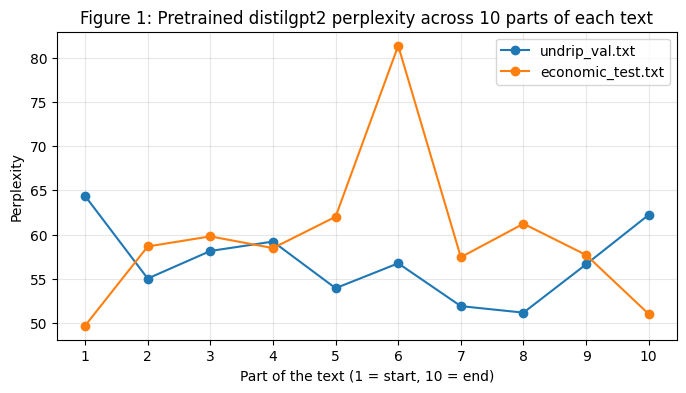

In [ ]:
# plot
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), valPpls, marker="o", label="undrip_val.txt")
plt.plot(range(1, 11), testPpls, marker="o", label="economic_test.txt")
plt.xlabel("Part of the text (1 = start, 10 = end)")
plt.ylabel("Perplexity")
plt.title("Figure 1: Pretrained distilgpt2 perplexity across 10 parts of each text")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
hardest = testPpls.index(max(testPpls))
easiest = testPpls.index(min(testPpls))

print("HARDEST test part: part", hardest + 1, "PPL =", round(testPpls[hardest], 2))
print(testParts[hardest][:400])
print()
print("EASIEST test part: part", easiest + 1, "PPL =", round(testPpls[easiest], 2))
print(testParts[easiest][:400])

HARDEST test part: part 6 PPL = 81.36
ents which are identified as containing ICIP within current laws.
An Indigenous Knowledge Panel is also being established to advise IP Australia on
traditional knowledge issues and ways to improve the IP system, and support
Aboriginal and Torres Strait Islander peoples, communities and business to protect
and benefit from their ICIP.
Dr Janke acknowledges the work currently being undertaken by the

EASIEST test part: part 1 PPL = 49.68
The inquiry
Referral of the inquiry
On 27 March 2024, the Committee adopted an inquiry into economic self-
determination and opportunities for First Nations Australians following a referral
from the then Minister for Indigenous Australians, the Hon Linda Burney MP.
The terms of reference for the inquiry are listed on page xv of this report.
Conduct of the inquiry
The Committee received 109 submiss


In [ ]:
icipCounts = []
for part in testParts:
    icipCounts.append(part.count("ICIP"))

partTable["Test ICIP count"] = icipCounts
print("Table 2: Pretrained perplexity for each 10% part of the text (with ICIP count)")
print(partTable.to_string(index=False))

print()
print("ICIP in undrip_train.txt :", trainText.count("ICIP"))
print("ICIP in undrip_val.txt   :", valText.count("ICIP"))
print("ICIP in economic_test.txt:", testText.count("ICIP"))

Table 2: Pretrained perplexity for each 10% part of the text (with ICIP count)
 Part  Val PPL  Val digits %  Test PPL  Test digits %  Test ICIP count
    1    64.36          0.77     49.68           0.80                0
    2    55.02          0.17     58.65           0.71                0
    3    58.14          0.17     59.79           0.24                0
    4    59.20          0.21     58.46           0.68                0
    5    53.93          0.41     62.01           0.59               13
    6    56.74          0.69     81.36           0.59               29
    7    51.90          0.67     57.44           0.62                6
    8    51.16          0.04     61.22           0.60                2
    9    56.63          0.17     57.69           0.32                0
   10    62.23          0.42     51.01           0.54                1

ICIP in undrip_train.txt : 2
ICIP in undrip_val.txt   : 0
ICIP in economic_test.txt: 51


# Full fine-tuning 

Fine-tune `distilgpt2` once using the fixed full fine-tuning configuration. Report the result in the master results table.


In [ ]:
full_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL)
full_model.resize_token_embeddings(len(tokenizer))
full_model.config.pad_token_id = tokenizer.pad_token_id

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

In [ ]:
blockSize = TOKENISATION_CONFIG["block_size"]

In [ ]:
def makeBlocks(text):
    tokenIds = tokenizer(text)["input_ids"]
    blocks = []
    # cut the long token list into pieces of 128 tokens (the last short piece is dropped)
    for start in range(0, len(tokenIds) - blockSize + 1, blockSize):
        blocks.append(tokenIds[start : start + blockSize])
    return Dataset.from_dict({"input_ids": blocks})

def countTrainableParams(model):
    total = 0
    for p in model.parameters():
        if p.requires_grad:
            total = total + p.numel()
    return total

In [ ]:
trainDataset = makeBlocks(trainText)
print("Training blocks of 128 tokens:", len(trainDataset))

# mlm=False = normal next-token prediction, the labels are a copy of input_ids
dataCollator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

with open("results.json") as f:
    results = json.load(f)

if Path("saved_full_model").exists() and "full" in results:
    # load the triend model from Drive
    print("Loading saved full fine-tuned model from Drive")
    full_model = AutoModelForCausalLM.from_pretrained("saved_full_model")
else:

    # always start training from a fresh pretrained model (never from an already trained one)
    full_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL)
    full_model.resize_token_embeddings(len(tokenizer))
    full_model.config.pad_token_id = tokenizer.pad_token_id

    fullParams = countTrainableParams(full_model)

    fullTrainingArgs = TrainingArguments(**FULL_FINE_TUNING_CONFIG)
    trainer = Trainer(
        model=full_model,
        args=fullTrainingArgs,
        train_dataset=trainDataset,
        data_collator=dataCollator
    )

    startTime = time.time()
    trainer.train()
    trainMinutes = (time.time() - startTime) / 60

    # keep the training loss for the loss curve
    lossSteps = []
    lossValues = []
    for log in trainer.state.log_history:
        if "loss" in log:
            lossSteps.append(log["step"])
            lossValues.append(log["loss"])

    # save the model and the numbers to Drive
    full_model.save_pretrained("saved_full_model")
    results["full"] = { "params_updated": fullParams, "train_time_min": trainMinutes,
        "loss_steps": lossSteps, "loss_values": lossValues}
    with open("results.json", "w") as f:
        json.dump(results, f, indent=2)

print("Parameters updated:", results["full"]["params_updated"])
print("Training time (minutes):", round(results["full"]["train_time_min"], 2))

Training blocks of 128 tokens: 459


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

{'loss': '3.835', 'grad_norm': '8.896', 'learning_rate': '4.587e-05', 'epoch': '0.08696'}
{'loss': '3.628', 'grad_norm': '9.552', 'learning_rate': '4.152e-05', 'epoch': '0.1739'}
{'loss': '3.522', 'grad_norm': '10.28', 'learning_rate': '3.717e-05', 'epoch': '0.2609'}
{'loss': '3.571', 'grad_norm': '9.938', 'learning_rate': '3.283e-05', 'epoch': '0.3478'}
{'loss': '3.467', 'grad_norm': '9.604', 'learning_rate': '2.848e-05', 'epoch': '0.4348'}
{'loss': '3.478', 'grad_norm': '10.09', 'learning_rate': '2.413e-05', 'epoch': '0.5217'}
{'loss': '3.353', 'grad_norm': '9.342', 'learning_rate': '1.978e-05', 'epoch': '0.6087'}
{'loss': '3.448', 'grad_norm': '10.63', 'learning_rate': '1.543e-05', 'epoch': '0.6957'}
{'loss': '3.415', 'grad_norm': '9.231', 'learning_rate': '1.109e-05', 'epoch': '0.7826'}
{'loss': '3.402', 'grad_norm': '10.44', 'learning_rate': '6.739e-06', 'epoch': '0.8696'}
{'loss': '3.411', 'grad_norm': '10.43', 'learning_rate': '2.391e-06', 'epoch': '0.9565'}
{'train_runtime': '1

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Parameters updated: 81912576
Training time (minutes): 0.24


### Full fine tuning investigation

**Prediction.** The aim here is to see if full fine tuning helps every part of economic_test.txt in the same way. My prediction is that PPL will go down in all 10 parts, but part 6 will improve the least.

**Rationale.** Part 6 was the hardest part in Task 1 (PPL 81.36), and a lot of it is about ICIP. But ICIP is used only 2 times in undrip_train.txt. So the model does not really get a chance to learn this topic during training. Parts that use normal committee language, like part 1, should improve more because that kind of language is all over the training text.

**How it will be tested.** The 10 part analysis from Task 1 is repeated with the full fine tuned model, and then the PPL drop for each part is compared. I decided to use the percentage drop instead of the normal drop. This is because part 6 starts much higher than the other parts, so its normal drop could look big even if the model did not actually learn it better.

## evidence



In [ ]:
fullValPpl = calculatePerplexity(full_model, valText)
fullTestPpl = calculatePerplexity(full_model, testText)

print("Full fine-tuned PPL on undrip_val.txt   :", round(fullValPpl, 2))
print("Full fine-tuned PPL on economic_test.txt:", round(fullTestPpl, 2))

# save to Drive
results["full"]["val_ppl"] = fullValPpl
results["full"]["test_ppl"] = fullTestPpl
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)

Full fine-tuned PPL on undrip_val.txt   : 30.24
Full fine-tuned PPL on economic_test.txt: 42.04


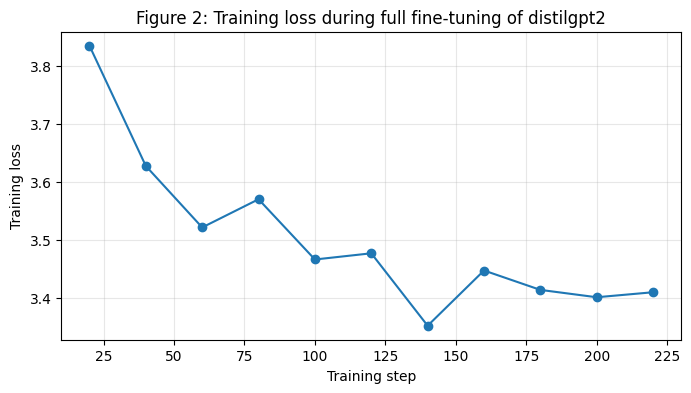

First logged loss: 3.8349
Final logged loss: 3.4105


In [ ]:
lossSteps = results["full"]["loss_steps"]
lossValues = results["full"]["loss_values"]

plt.figure(figsize=(8, 4))
plt.plot(lossSteps, lossValues, marker="o")
plt.xlabel("Training step")
plt.ylabel("Training loss")
plt.title("Figure 2: Training loss during full fine-tuning of distilgpt2")
plt.grid(alpha=0.3)
plt.show()

print("First logged loss:", round(lossValues[0], 4))
print("Final logged loss:", round(lossValues[-1], 4))

In [ ]:
preTestPartPpls = []
fullTestPartPpls = []
improvements = []

for i in range(10):
    prePpl = calculatePerplexity(pretrained_model, testParts[i])
    fullPpl = calculatePerplexity(full_model, testParts[i])
    drop = (prePpl - fullPpl) / prePpl * 100   # percentage drop
    preTestPartPpls.append(prePpl)
    fullTestPartPpls.append(fullPpl)
    improvements.append(drop)

fullPartTable = pd.DataFrame({
    "Part": list(range(1, 11)),
    "Pretrained PPL": preTestPartPpls,
    "Full FT PPL": fullTestPartPpls,
    "Drop %": improvements,
    "ICIP count": icipCounts
}).round(2)

Table 4: Economic test PPL for each 10% part, pretrained vs full fine-tuned
 Part  Pretrained PPL  Full FT PPL  Drop %  ICIP count
    1           49.68        34.08   31.40           0
    2           58.65        42.45   27.63           0
    3           59.79        42.86   28.32           0
    4           58.46        42.25   27.73           0
    5           62.01        44.92   27.56          13
    6           81.36        59.42   26.96          29
    7           57.44        40.18   30.04           6
    8           61.22        43.67   28.67           2
    9           57.69        41.55   27.97           0
   10           51.01        33.87   33.60           1

Part with the smallest drop: 6
Part with the biggest drop : 10


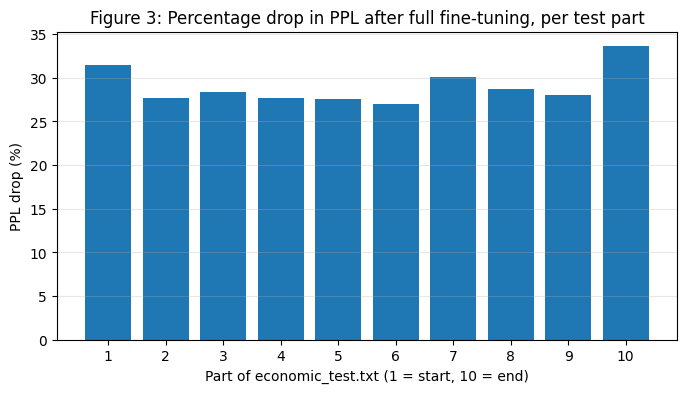

In [ ]:
print("Table 4: Economic test PPL for each 10% part, pretrained vs full fine-tuned")
print(fullPartTable.to_string(index=False))

leastPart = improvements.index(min(improvements)) + 1
mostPart = improvements.index(max(improvements)) + 1
print()
print("Part with the smallest drop:", leastPart)
print("Part with the biggest drop :", mostPart)

plt.figure(figsize=(8, 4))
plt.bar(range(1, 11), improvements)
plt.xlabel("Part of economic_test.txt (1 = start, 10 = end)")
plt.ylabel("PPL drop (%)")
plt.title("Figure 3: Percentage drop in PPL after full fine-tuning, per test part")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3, axis="y")
plt.show()

### Investigation results and interpretation

**Evidence.** Table 4 and Figure 3 show that all 10 parts improved after full fine tuning. Part 6 had the smallest drop (26.96%, from 81.36 to 59.42) and part 10 the biggest (33.60%).

**Interpretation.** But the support is weak. Part 5 dropped 27.56%, only 0.6% more than part 6, and parts 2 and 4 have no ICIP but still dropped almost the same (27.63% and 27.73%). The unexpected thing is how similar all the drops are, between 27% and 34%.

**Limitation.** This is one run with one seed, so differences could just be noise. Also the parts are cut by characters, so each part mixes different topics.

LoRA adaptation and comparison (25%)

Train a LoRA-adapted version of `distilgpt2` using the fixed LoRA configuration. Reload a fresh distilgpt2 base model before applying LoRA. Do not apply LoRA to the full fine-tuned model from Task 2.
Report the result in the master results table.


In [ ]:
lora_base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL)
lora_base_model.resize_token_embeddings(len(tokenizer))
lora_base_model.config.pad_token_id = tokenizer.pad_token_id

lora_training_args = TrainingArguments(**LORA_TRAINING_CONFIG)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

In [ ]:
if Path("saved_lora_model").exists() and "lora" in results:
    # already trained before, so just load the adapter from Drive
    print("Loading saved LoRA adapter from Drive")
    lora_model = PeftModel.from_pretrained(lora_base_model, "saved_lora_model")
else:
    # add the small LoRA matrices to the fresh base model
    loraConfig = LoraConfig(**LORA_CONFIG)
    lora_model = get_peft_model(lora_base_model, loraConfig)

    # only the LoRA matrices are trainable now, the original weights are frozen
    loraParams = countTrainableParams(lora_model)

    trainer = Trainer(
        model=lora_model,
        args=lora_training_args,
        train_dataset=trainDataset,
        data_collator=dataCollator
    )

    startTime = time.time()
    trainer.train()
    trainMinutes = (time.time() - startTime) / 60

    lossSteps = []
    lossValues = []
    for log in trainer.state.log_history:
        if "loss" in log:
            lossSteps.append(log["step"])
            lossValues.append(log["loss"])

    # save only the LoRA adapter (very small) and the numbers to Drive
    lora_model.save_pretrained("saved_lora_model")
    results["lora"] = {
        "params_updated": loraParams,
        "train_time_min": trainMinutes,
        "loss_steps": lossSteps,
        "loss_values": lossValues
    }
    with open("results.json", "w") as f:
        json.dump(results, f, indent=2)

print("Parameters updated:", results["lora"]["params_updated"])
print("Training time (minutes):", round(results["lora"]["train_time_min"], 2))

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2631: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


{'loss': '4.012', 'grad_norm': '0.2134', 'learning_rate': '9.174e-05', 'epoch': '0.08696'}
{'loss': '4.003', 'grad_norm': '0.341', 'learning_rate': '8.304e-05', 'epoch': '0.1739'}
{'loss': '3.936', 'grad_norm': '0.4132', 'learning_rate': '7.435e-05', 'epoch': '0.2609'}
{'loss': '3.98', 'grad_norm': '0.4439', 'learning_rate': '6.565e-05', 'epoch': '0.3478'}
{'loss': '3.913', 'grad_norm': '0.4531', 'learning_rate': '5.696e-05', 'epoch': '0.4348'}
{'loss': '3.898', 'grad_norm': '0.5348', 'learning_rate': '4.826e-05', 'epoch': '0.5217'}
{'loss': '3.808', 'grad_norm': '0.6885', 'learning_rate': '3.957e-05', 'epoch': '0.6087'}
{'loss': '3.885', 'grad_norm': '0.6489', 'learning_rate': '3.087e-05', 'epoch': '0.6957'}
{'loss': '3.877', 'grad_norm': '0.5505', 'learning_rate': '2.217e-05', 'epoch': '0.7826'}
{'loss': '3.839', 'grad_norm': '0.6754', 'learning_rate': '1.348e-05', 'epoch': '0.8696'}
{'loss': '3.859', 'grad_norm': '0.5573', 'learning_rate': '4.783e-06', 'epoch': '0.9565'}
{'train_run

In [ ]:
loraValPpl = calculatePerplexity(lora_model, valText)
loraTestPpl = calculatePerplexity(lora_model, testText)

print("LoRA PPL on undrip_val.txt   :", round(loraValPpl, 2))
print("LoRA PPL on economic_test.txt:", round(loraTestPpl, 2))

results["lora"]["val_ppl"] = loraValPpl
results["lora"]["test_ppl"] = loraTestPpl
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)

LoRA PPL on undrip_val.txt   : 45.83
LoRA PPL on economic_test.txt: 49.93


## Generation comparison table

Use the fixed generation prompt exactly. Keep outputs short enough to be readable in the exported PDF.

**Table 5: Generation comparison using the fixed prompt** (greedy decoding, 80 new tokens; "/" marks a line break in the output)

| Prompt | Pretrained output | Full fine-tuned output | LoRA-adapted output | One-sentence comparison |
|---|---|---|---|---|
| `Economic self-determination for First Nations peoples requires` | a strong commitment to the rights of all peoples. (followed by 70 empty lines) | a comprehensive and comprehensive and comprehensive approach to the rights of First Nations peoples. / The UN Declaration on the Rights of Indigenous Peoples states: / The Declaration on the Rights of Indigenous Peoples states: (this line repeats 3 more times, then is cut off) | a comprehensive and comprehensive international framework for the development of the peoples of the world. / The Declaration of Independence of the United States of America states: (this line repeats 3 more times, then is cut off) | The pretrained model gives one general sentence and then only empty lines, the full fine tuned model stays on the UNDRIP topic but repeats the same line, and LoRA starts in a similar way but drifts to the US Declaration of Independence, so none of them really talks about the economic topic of the prompt. |

In [ ]:
def generateText(model, prompt):
    model.to(device)
    model.eval()
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        output = model.generate(**inputs, **GENERATION_CONFIG, pad_token_id=tokenizer.eos_token_id)
    # keep only the new tokens, not the prompt again
    newTokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(newTokens, skip_special_tokens=True)

In [ ]:
pretrainedOutput = generateText(pretrained_model, GENERATION_PROMPT)
fullOutput = generateText(full_model, GENERATION_PROMPT)
loraOutput = generateText(lora_model, GENERATION_PROMPT)

print("PROMPT:", GENERATION_PROMPT)
print()
print("Pretrained")
print(pretrainedOutput)
print()
print("Full fine-tuned")
print(fullOutput)
print()
print("LoRA")
print(loraOutput)

PROMPT: Economic self-determination for First Nations peoples requires

Pretrained
 a strong commitment to the rights of all peoples.







































































Full fine-tuned
 a comprehensive and comprehensive and comprehensive approach to the rights of First Nations peoples.
The UN Declaration on the Rights of Indigenous Peoples states:
The Declaration on the Rights of Indigenous Peoples states:
The Declaration on the Rights of Indigenous Peoples states:
The Declaration on the Rights of Indigenous Peoples states:
The Declaration on the Rights of Indigenous Peoples states:
The Declaration on the Rights of Indigenous Peoples

LoRA
 a comprehensive and comprehensive international framework for the development of the peoples of the world.
The Declaration of Independence of the United States of America states:
The Declaration of Independence of the United States of America states:
The Declaration of Independence of the United States of America 

In [ ]:
def cleanForTable(text):
    # remove empty lines and join the rest with " / " so it fits in one table cell
    lines = []
    for line in text.split("\n"):
        if line.strip() != "":
            lines.append(line.strip())
    return " / ".join(lines)

print("New line characters in each output:")
print("Pretrained     :", pretrainedOutput.count("\n"))
print("Full fine-tuned:", fullOutput.count("\n"))
print("LoRA           :", loraOutput.count("\n"))
print()
print("Pretrained     :", cleanForTable(pretrainedOutput))
print()
print("Full fine-tuned:", cleanForTable(fullOutput))
print()
print("LoRA           :", cleanForTable(loraOutput))

New line characters in each output:
Pretrained     : 70
Full fine-tuned: 6
LoRA           : 5

Pretrained     : a strong commitment to the rights of all peoples.

Full fine-tuned: a comprehensive and comprehensive and comprehensive approach to the rights of First Nations peoples. / The UN Declaration on the Rights of Indigenous Peoples states: / The Declaration on the Rights of Indigenous Peoples states: / The Declaration on the Rights of Indigenous Peoples states: / The Declaration on the Rights of Indigenous Peoples states: / The Declaration on the Rights of Indigenous Peoples states: / The Declaration on the Rights of Indigenous Peoples

LoRA           : a comprehensive and comprehensive international framework for the development of the peoples of the world. / The Declaration of Independence of the United States of America states: / The Declaration of Independence of the United States of America states: / The Declaration of Independence of the United States of America states: / The

#### LoRA Behaviour Investigation

In [ ]:
fullSteps = results["full"]["loss_steps"]
fullLoss = results["full"]["loss_values"]
loraSteps = results["lora"]["loss_steps"]
loraLoss = results["lora"]["loss_values"]

# how much of the full fine-tuning gain did LoRA get?
preVal = results["pretrained"]["val_ppl"]
fullVal = results["full"]["val_ppl"]
loraVal = results["lora"]["val_ppl"]
fullGain = preVal - fullVal
loraGain = preVal - loraVal
print("Val PPL gain, full fine-tuned:", round(fullGain, 2))
print("Val PPL gain, LoRA           :", round(loraGain, 2))
print("LoRA got", round(loraGain / fullGain * 100, 1), "% of the full fine-tuning gain")
print()

lossTable = pd.DataFrame({
    "Model": ["Full fine-tuned", "LoRA"],
    "First logged loss": [fullLoss[0], loraLoss[0]],
    "Final logged loss": [fullLoss[-1], loraLoss[-1]],
    "Loss drop": [fullLoss[0] - fullLoss[-1], loraLoss[0] - loraLoss[-1]],
    "exp(final loss)": [math.exp(fullLoss[-1]), math.exp(loraLoss[-1])],
    "Val PPL": [fullVal, loraVal]
}).round(3)

Val PPL gain, full fine-tuned: 25.24
Val PPL gain, LoRA           : 9.66
LoRA got 38.3 % of the full fine-tuning gain



Table 6: Training loss compared with validation PPL
          Model  First logged loss  Final logged loss  Loss drop  exp(final loss)  Val PPL
Full fine-tuned              3.835              3.411      0.424           30.281   30.244
           LoRA              4.012              3.859      0.154           47.399   45.826

Pretrained val PPL as a loss (log of 55.49): 4.016


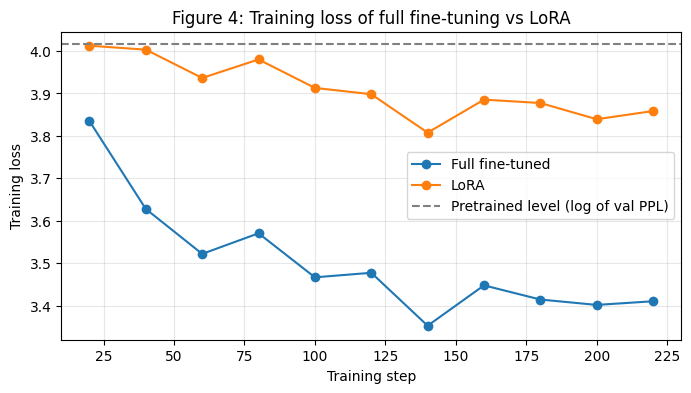

In [ ]:
print("Table 6: Training loss compared with validation PPL")
print(lossTable.to_string(index=False))
print()
print("Pretrained val PPL as a loss (log of 55.49):", round(math.log(preVal), 3))

plt.figure(figsize=(8, 4))
plt.plot(fullSteps, fullLoss, marker="o", label="Full fine-tuned")
plt.plot(loraSteps, loraLoss, marker="o", label="LoRA")
plt.axhline(math.log(preVal), color="gray", linestyle="--", label="Pretrained level (log of val PPL)")
plt.xlabel("Training step")
plt.ylabel("Training loss")
plt.title("Figure 4: Training loss of full fine-tuning vs LoRA")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Investigation answer

**Behaviour identified.** LoRA was expected to get most of the gain of full fine tuning on undrip_val.txt, because it was trained on the same report. But it only brought val PPL from 55.49 to 45.83, while full fine tuning reached 30.24. So LoRA got only about 38% of the gain (9.66 out of 25.24).

**Investigation and evidence.** To check why, the training loss of both runs was plotted together (Figure 4, Table 6). Full fine tuning went from 3.835 to 3.411, but LoRA only from 4.012 to 3.859. LoRA's first loss is almost at the pretrained level (about 4.02), so it hardly changed the model in the first 20 steps. The exp of the final training loss is also close to each val PPL (30.3 against 30.24 for full, 47.4 against 45.83 for LoRA). So the gap is not overfitting. LoRA just learned less.

**Explanation.** LoRA only trains 147,456 parameters (about 0.18% of the model), all in the attention layers. The word embeddings and feed forward layers stay frozen, so the vocabulary and style knowledge stored there cannot change. With one epoch, this small update was not enough to catch up.

**Limitation.** The two runs used different learning rates (0.0001 and 0.00005), so this analysis cannot separate the effect of the small rank, the short training and the learning rate. That would need extra runs outside the fixed protocol.